# **Hotel Booking Demand**

### **Context**

## **Business Problem Understanding**

Bisnis industri perhotelan bertumpu kepada tingkat pemesanan/booking kamar sebagai sumber pendapatan utama hotel, salah satu resiko yang menjadi permasalahan dalam industri perhotelan yaitu resiko pembatalan (cancellation) booking dari customer. Hal tersebut dapat menyebabkan hotel kehilangan revenue karena kamar yang sudah dibooking sulit untuk dijual kembali dan mengganggu management waktu operasional hotel.
Oleh sebab itu management hotel perlu mengetahui dan menganalisis customer yang memiliki potensi membatalkan reservasi dengan menggunakan pendekatan data analysis dan machine learning.

City hotel dan resort hotel kerap mengalami pembatalan (cancellation) dari customer, yang dapat berdampak signifikan terhadap bisnis hotel. Pembatalan ini menyebabkan potensi kehilangan pendapatan karena hotel telah mempersiapkan kedatangan tamu, seperti mengosongkan kamar dan mengatur operasional lainnya. Oleh karena itu, hotel perlu mengetahui dan memprediksi customer mana yang benar-benar akan datang dan mana yang berpotensi membatalkan reservasi dengan menganalisis berbagai informasi, seperti waktu pemesanan, lama menginap, jumlah orang dewasa, anak-anak dan/atau bayi, serta ketersediaan tempat parkir, dan faktor-faktor relevan lainnya.

Target:


*   0: Tidak Batal
*   1: Batal


Stakeholder: Operational Hotel

### **Problem Statement**

Booking cancellations dalam industri perhotelan memiliki dampak signifikan terhadap manajemen permintaan dan kinerja bisnis hotel. Pembatalan menghambat penyusunan peramalan permintaan yang akurat, yang merupakan komponen penting dalam revenue management. Selain itu, pembatalan juga menyebabkan potensi kehilangan pendapatan karena hotel telah mempersiapkan operasional sebelum kedatangan tamu, seperti mengalokasikan kamar, menyiapkan sumber daya manusia, dan mengatur layanan pendukung lainnya.

### **Goals**

Tujuan dari analisa ini adalah :
1. Memprediksi pembatalan reservasi customer sehingga hotel dapat mengantisipasi potensi pembatalan lebih awal dan menurunkan cancellation rate.
2. Menganalisis faktor-faktor yang mempengaruhi pembatalan reservasi customer, sehingga hotel dapat melakukan perbaikan bisnis yang strategis.

### **Analytic Approach**

Booking cancellation merupakan permasalahan serius dalam industri perhotelan karena berdampak langsung pada pendapatan dan perencanaan operasional. Studi menunjukkan bahwa cancellation rate hotel dapat mencapai 37–40% dari total reservasi, yang berarti hampir setengah kamar yang telah dipesan berpotensi tidak terisi . (https://bright-journal.org/Journal/index.php/JADS/article/view/165)).

Di sisi lain, untuk mengurangi risiko kamar kosong akibat pembatalan, hotel cenderung menerapkan strategi overbooking (https://medium.com/@guyshazam12/cancel-less-stay-more-an-ai-model-to-predict-hotel-booking-cancellations-cf6aa159dd90), yaitu menerima jumlah reservasi melebihi kapasitas kamar dengan asumsi sebagian customer akan membatalkan pesanan mereka. Namun, strategi ini dapat menyebabkan jumlah tamu yang datang melebihi kapasitas hotel, sehingga hotel harus menolak atau memindahkan tamu (walk guest), yang berdampak pada biaya kompensasi dan reputasi hotel. Oleh karena itu diperlukan analisis kuantitatif untuk membandingkan dampak kerugian dari kedua kondisi tersebut.



---


**Contoh Perhitungan Kerugian:**

**Asumsi**
*   Jumlah kamar hotel: 100 kamar
*   Total kapasitas kamar per bulan: 30 x 100 = 3,000 kamar
*   Average Daily Rate (ADR): 100 USD / malam (sesuai dataset)
*   Cancellation rate per bulan: 37% (sesuai dataset)

---
**Kerugian Pembatalan Sebelum Menggunakan Model ML**
* **Total kamar yang dibatalkan dalam sebulan:** 37% × 3000 = 1,110 kamar
* **Revenue Loss/Bulan:** 1,110 x 100 USD = 111,000 USD

---

**Kerugian Overbooking Sebelum Menggunakan Model ML**

Karena 37% booking dibatalkan, hotel biasanya melakukan overbooking untuk menghindari kamar kosong. Misalnya hotel mengantisipasi 37 kamar cancel, maka hotel menerima 137 booking untuk 100 kamar. Walk guest hanya terjadi jika cancellation aktual lebih rendah dari 37%. Berdasarkan analisis data historis, tingkat cancellation terendah per bulan adalah 30%.

* Jumlah kamar hotel: 100 kamar
* Total booking: 137 kamar
* Cancellation aktual bulanan = 30%
* Jumlah Kamar Terisi: 137 × (1 − 0.30) = 95.9 ≈ 96 kamar (**tidak ada walk guest**)





---


Dengan asumsi rata-rata **cancellation rate sebesar 37%, hotel berpotensi mengalami kerugian pendapatan sekitar USD 110,000 per bulan akibat kamar yang tidak terjual**, sementara pada skenario **cancellation terendah secara bulanan (30%), strategi overbooking tidak menimbulkan walk guest dan tetap menghasilkan kerugian akibat kamar kosong**. Dengan demikian, **kerugian akibat tingginya tingkat pembatalan reservasi jauh lebih besar dibandingkan risiko overbooking**


















### **Metric Evaluation**

Berdasarkan konsekuensi kerugiannya, maka kita harus berusaha untuk mengurangi biaya pembatalan booking oleh customer dengan mengurangi **False Negative Rate**, yaitu kondisi ketika booking yang sebenarnya batal justru diprediksi sebagai tidak batal. Oleh karena itu, fokus evaluasi model diarahkan pada metrik yang menekankan kemampuan mendeteksi customer berisiko batal, yaitu:

**Recall:** Mengukur seberapa banyak customer batal booking yang berhasil terdeteksi dengan benar oleh model.


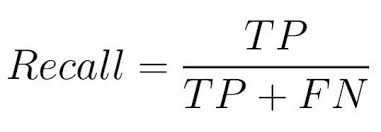

### **Limitation**

- Dataset tidak menyediakan booking ID unik, sehingga potensi duplikasi data tidak dapat diverifikasi secara pasti, dan setiap observasi diasumsikan sebagai reservasi yang valid.
- Model ini dilatih menggunakan data booking periode 2015–2017.
Oleh karena itu, prediksi dibatasi pada rentang waktu tersebut (historical behavior prediction)
untuk menjaga konsistensi distribusi data dan reliabilitas prediksi.

## **Data Understanding**

Untuk mendukung analisis, dipakai dua dataset permintaan hotel, yaitu Resort Hotel (H1) dan City Hotel (H2), yang memiliki struktur data yang sama dengan 31 variabel. Dataset H1 terdiri dari 40.060 observasi dan H2 sebanyak 79.330 observasi, di mana setiap observasi merepresentasikan satu pemesanan hotel di Negara Portugal dan data ini mencakup pemesanan dengan tanggal kedatangan antara 1 Juli 2015 hingga 31 Agustus 2017.

Dengan demikian, seluruh proses eksplorasi data, analisis difokuskan pada rentan waktu tersebut.

Sedangkan pengembangan model prediksi pembatalan pemesanan digunakan untuk strategi di 2 tahun berikutnya.

Data Source: https://www.kaggle.com/jessemostipak/hotel-booking-demand/data

| Attribute | Description |
|------------|---------------|
| **hotel** | Resort Hotel or City Hotel. |
| **is_canceled** | Value indicating if the booking was canceled (1) or not (0). |
| **lead_time** | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date. |
| **arrival_date_year** | Year of arrival date. |
| **arrival_date_month** | Month of arrival date. |
| **arrival_date_week_number** | Week number of year for arrival date. |
| **arrival_date_day_of_month** | Day of arrival date. |
| **stays_in_weekend_nights** | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel. |
| **stays_in_week_nights** | Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel. |
| **adults** | Number of adults. |
| **babies** | Number of babies. |
| **meal** | Type of meal booked. Categories are presented in standard hospitality meal packages: Undefined/SC – no meal package; BB – Bed & Breakfast; HB – Half board (breakfast and one other meal – usually dinner); FB – Full board (breakfast, lunch and dinner). |
| **country** | Country of origin. |
| **market_segment** | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators”. |
| **distribution_channel** | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators”. |
| **is_repeated_guest** | Value indicating whether the booking was made by a repeated guest (1) or not (0). |
| **previous_cancellations** | Number of previous bookings that were canceled by the customer before the current booking. |
| **previous_bookings_not_canceled** | Number of previous bookings not canceled by the customer before the current booking. |
| **reserved_room_type** | Code representing the room type reserved. The code is used instead of the actual room designation for anonymity purposes. |
| **assigned_room_type** | Code representing the room type assigned to the booking. The assigned room type may differ from the reserved room type due to hotel operational reasons such as overbooking or due to customer requests. |
| **booking_changes** | Number of changes or amendments made to the booking after it was created. |
| **deposit_type** | Type of deposit applied to the booking: No Deposit means no deposit was made; Non Refund means a deposit equal to the total stay cost was made; Refundable means a deposit below the total cost of stay was made. |
| **agent** | Identifier of the travel agency that made the booking. The identifier is anonymized. |
| **company** | Identifier of the company or entity responsible for making or paying for the booking. The identifier is anonymized. |
| **days_in_waiting_list** | Number of days the booking remained on the waiting list before it was confirmed to the customer. |
| **customer_type** | Type of customer: Group indicates the booking is associated with a group; Transient indicates the booking is not part of a group or contract; Transient-party indicates the booking is transient but associated with at least one other transient booking. |
| **adr** | Average Daily Rate, calculated by dividing the total lodging revenue by the total number of staying nights. |
| **required_car_parking_spaces** | Number of car parking spaces required by the customer for the booking. |
| **total_of_special_requests** | Number of special requests made by the customer, such as requesting a twin bed or a high-floor room. |
| **reservation_status** | Final reservation status of the booking, such as Check-Out (the customer checked in and has departed) or No-Show (the customer did not check in but informed the hotel). |
| **reservation_status_date** | Date on which the last reservation status was set, indicating when the booking was canceled or when the customer checked out. |

### **Import Library**

In [146]:
# Library
import pandas as pd
import numpy as np
import math
from scipy.stats import shapiro
from scipy.stats import chi2_contingency

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [147]:
data = "https://raw.githubusercontent.com/Lutfiaryadi/FinalProject/refs/heads/main/hotel_bookings.csv"
df = pd.read_csv(data)
display(df.head(), df.tail())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [148]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [149]:
df.shape

(119390, 32)

Dataset ini terdiri dari 119.390 data booking dengan 32 variabel yang merepresentasikan karakteristik setiap reservasi hotel.

In [150]:
ListItem = []
for col in df.columns :
    ListItem.append([col, df[col].dtype, df[col].isna().sum(), round((df[col].isna().sum()/len(df[col])) * 100,2),
                    df[col].nunique(), list(df[col].drop_duplicates().values)]);

dfDesc = pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'],
                     data=ListItem)
dfDesc

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,hotel,object,0,0.00,2,"[Resort Hotel, City Hotel]"
1,is_canceled,int64,0,0.00,2,"[0, 1]"
2,lead_time,int64,0,0.00,479,"[342, 737, 7, 13, 14, 0, 9, 85, 75, 23, 35, 68..."
3,arrival_date_year,int64,0,0.00,3,"[2015, 2016, 2017]"
4,arrival_date_month,object,0,0.00,12,"[July, August, September, October, November, D..."
5,arrival_date_week_number,int64,0,0.00,53,"[27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 3..."
6,arrival_date_day_of_month,int64,0,0.00,31,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
7,stays_in_weekend_nights,int64,0,0.00,17,"[0, 1, 2, 4, 3, 6, 13, 8, 5, 7, 12, 9, 16, 18,..."
8,stays_in_week_nights,int64,0,0.00,35,"[0, 1, 2, 3, 4, 5, 10, 11, 8, 6, 7, 15, 9, 12,..."
9,adults,int64,0,0.00,14,"[2, 1, 3, 4, 40, 26, 50, 27, 55, 0, 20, 6, 5, 10]"


In [151]:
# Data Numeric Describe
numeric_desc = df.describe()
categoric_desc = df.describe(include='object')

display(numeric_desc, categoric_desc)

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [152]:
df_copy = df.copy()

## **Data Cleaning**

### Handling Missing Values
Penanganan missing values dilakukan dengan mempertimbangkan data penting pada dataset ini agar tidak menghilangkan informasi penting dalam pengolahan data.

In [153]:
missing = df.isna().sum()
missing_percent = (missing / len(df)) * 100

pd.DataFrame({
    'missing_count' : missing,
    'missing_percent' : missing_percent
}).sort_values(by='missing_percent', ascending=False)

,missing_count,missing_percent
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350
arrival_date_month,0,0.000000
arrival_date_week_number,0,0.000000
hotel,0,0.000000
is_canceled,0,0.000000
stays_in_weekend_nights,0,0.000000
arrival_date_day_of_month,0,0.000000


Pada variabel Agent dan Company, nilai NULL tidak dianggap sebagai data hilang, melainkan sebagai kondisi “tidak berlaku”. Nilai NULL pada Agent menunjukkan bahwa reservasi tidak dilakukan melalui agen perjalanan, sedangkan NULL pada Company mengindikasikan bahwa pembayaran tidak ditanggung oleh perusahaan, melainkan oleh customer individu. Sementara itu, nilai NULL pada variabel Children diartikan sebagai tidak adanya anak kecil dalam reservasi tersebut. Adapun nilai NULL pada Country merepresentasikan asal negara yang tidak diketahui

In [154]:
df['company'] = df['company'].fillna(0)
df['agent'] = df['agent'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['children'] = df['children'].fillna(0)

Penanganan nilai NULL dilakukan dengan mengganti Children menjadi 0, serta Agent dan Company menjadi 0, sementara Country diisi sebagai “Unknown”. Kemudian dilakukan pengecekkan kembali bahwa sudah tidak ada missing values.

In [155]:
df.isna().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


### Handling Duplicates Value
Duplikasi data kemungkinan berasal dari proses pencatatan booking yang dilakukan lebih dari satu kali. Handling duplikasi dilakukan untuk menghindari bias pada analisis dan model dan tergantung kepada seberapa besar duplikasi berpengaruh kepada data. Oleh karena itu kita coba lakukan pengecekan terlebih dahulu.

In [156]:
df.duplicated().sum()

np.int64(31994)

In [157]:
dup_rows = df[df.duplicated(keep=False)]
dup_rows

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,0.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,0.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,0.0,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119372,City Hotel,0,175,2017,August,35,31,1,3,1,...,No Deposit,42.0,0.0,0,Transient,82.35,0,1,Check-Out,2017-09-04


In [158]:
df.nunique().sort_values()

,0
hotel,2
is_canceled,2
is_repeated_guest,2
arrival_date_year,3
deposit_type,3
reservation_status,3
customer_type,4
babies,5
meal,5
distribution_channel,5


Dari hasil pengecekan terdapat data yang duplicated, keputusannya adalah daya tersebut tidak didrop karena setiap baris dan kolom dari setiap variabel mencerminkan nilai dari suatu transaksi booking hotel dan tidak terdapat ID unik yang di mana untuk memastikan duplikasi dari kesalahan pencatatan.

### Inconsistent Values

Melakukan pengecekkan dan handling inconsistent value dari column yang akan digunakan untuk analisa & modeling, seperti adr, adults, childern, babies, lead_time yang memiliki nilai yang aneh.

In [159]:
# lead_time
df[df['lead_time'] < 0].shape

(0, 32)

Tidak ditemukan adanya ke anehan.

In [160]:
# adr
df[df['adr'] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,No Deposit,273.0,0.0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


Ditemukan adanya nilai adr negatif yang secara logika tidak mungkin terjadi pada harga kamar hotel apabila nilainya negatif. Oleh karena itu, hasil dengan nilai adr < 0 dihapus dari dataset.

In [161]:
df = df[df['adr'] >= 0]
df.shape

(119389, 32)

In [162]:
df['total_guest'] = df['adults'] + df['children'] + df['babies']
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,0.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2.0


Perlu ditambahkan 'total_guest' sebagai total orang yang menginap untuk mempermudah mengetahui data lebih lanjut.

In [163]:
df[df['total_guest'] == 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,0.0,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,0.0
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,0.0,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,0.0
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,38.0,0.0,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,0.0
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,0.0
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,7.0,0.0,0,Transient,100.80,0,0,Check-Out,2017-06-30,0.0
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,0.0,0.0,0,Transient,0.00,1,1,Check-Out,2017-07-01,0.0
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,425.0,0.0,0,Transient,73.80,0,0,Check-Out,2017-07-17,0.0
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,9.0,0.0,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,0.0


Masih terdapat total guest dengan jumlah 0, oleh karena itu kami memutuskan untuk dilakukan drop karena tidak merepresentasikan pemesanan dengan informasi jumlah tamu. Pembatasan ini dilakukan untuk memastikan bahwa analisis dan pemodelan difokuskan pada pemesanan yang secara jelas.

In [164]:
df = df[df['total_guest'] > 0]
df.shape

(119209, 33)

### **Remove Unused Column**

In [165]:
df.drop(columns=['adults', 'children', 'babies'], inplace=True)
df.shape

(119209, 30)

Columns adults, children, babies diremove karena berpotensi menambahkan noise pada model. Penghapusan dilakukan untuk menyederhanakan model tanpa menghilangkan informasi penting.

### **Handling Outliers**

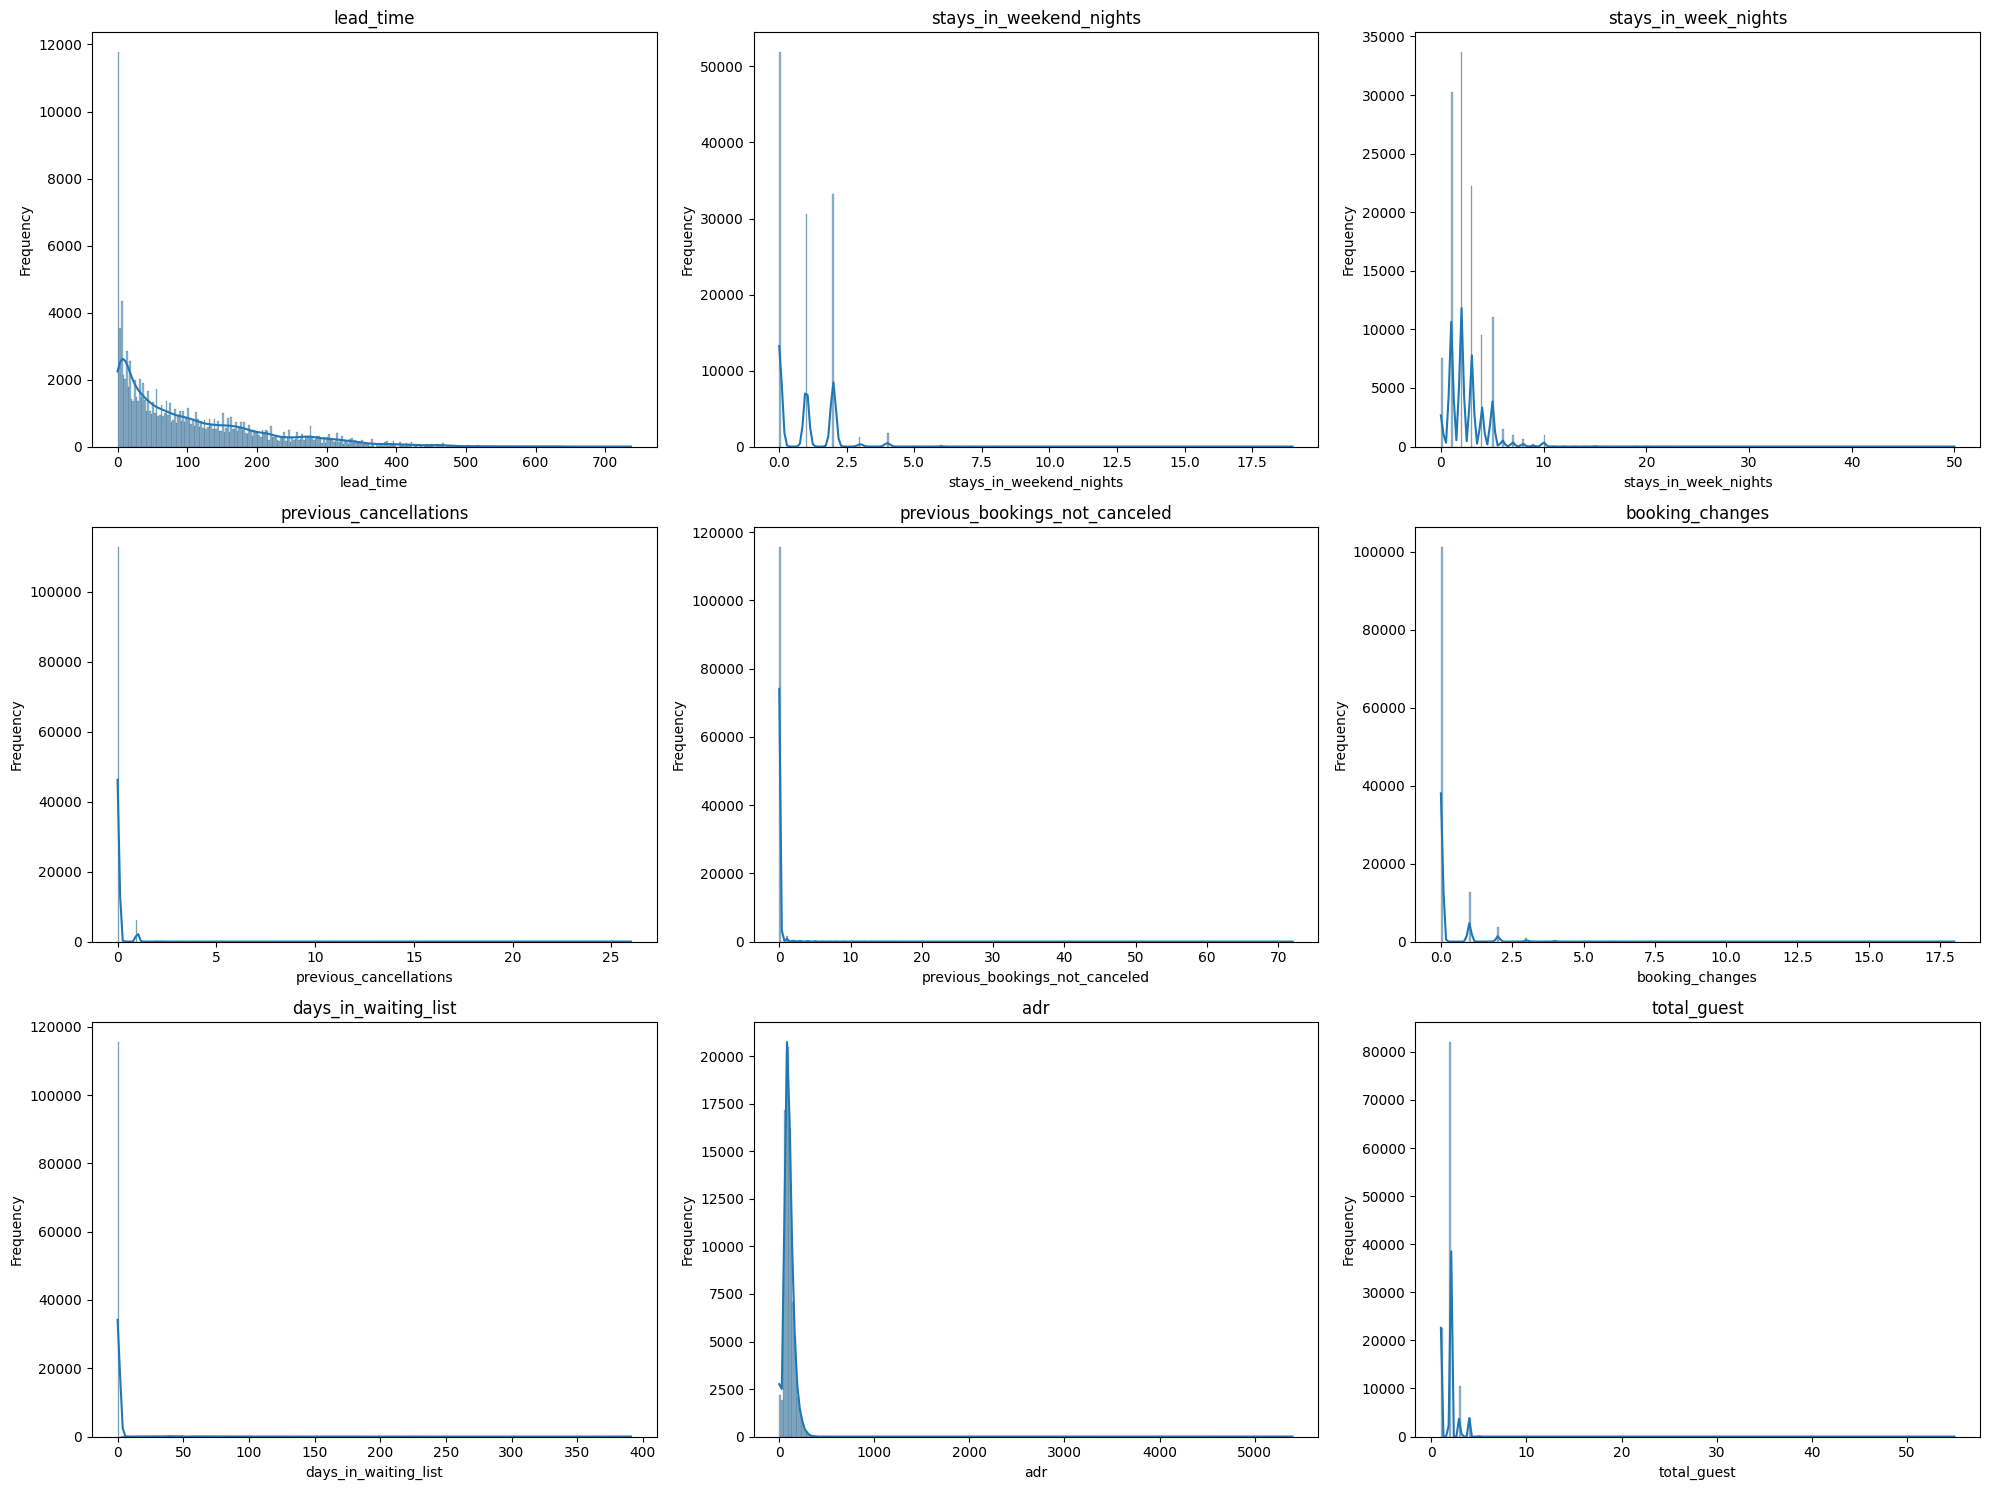

In [166]:
numeric_cols = ['lead_time',
       'stays_in_weekend_nights', 'stays_in_week_nights',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'booking_changes', 'days_in_waiting_list', 'adr',
       'total_guest']

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(20, 5 * n_rows))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df[col], bins=310, kde=True)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

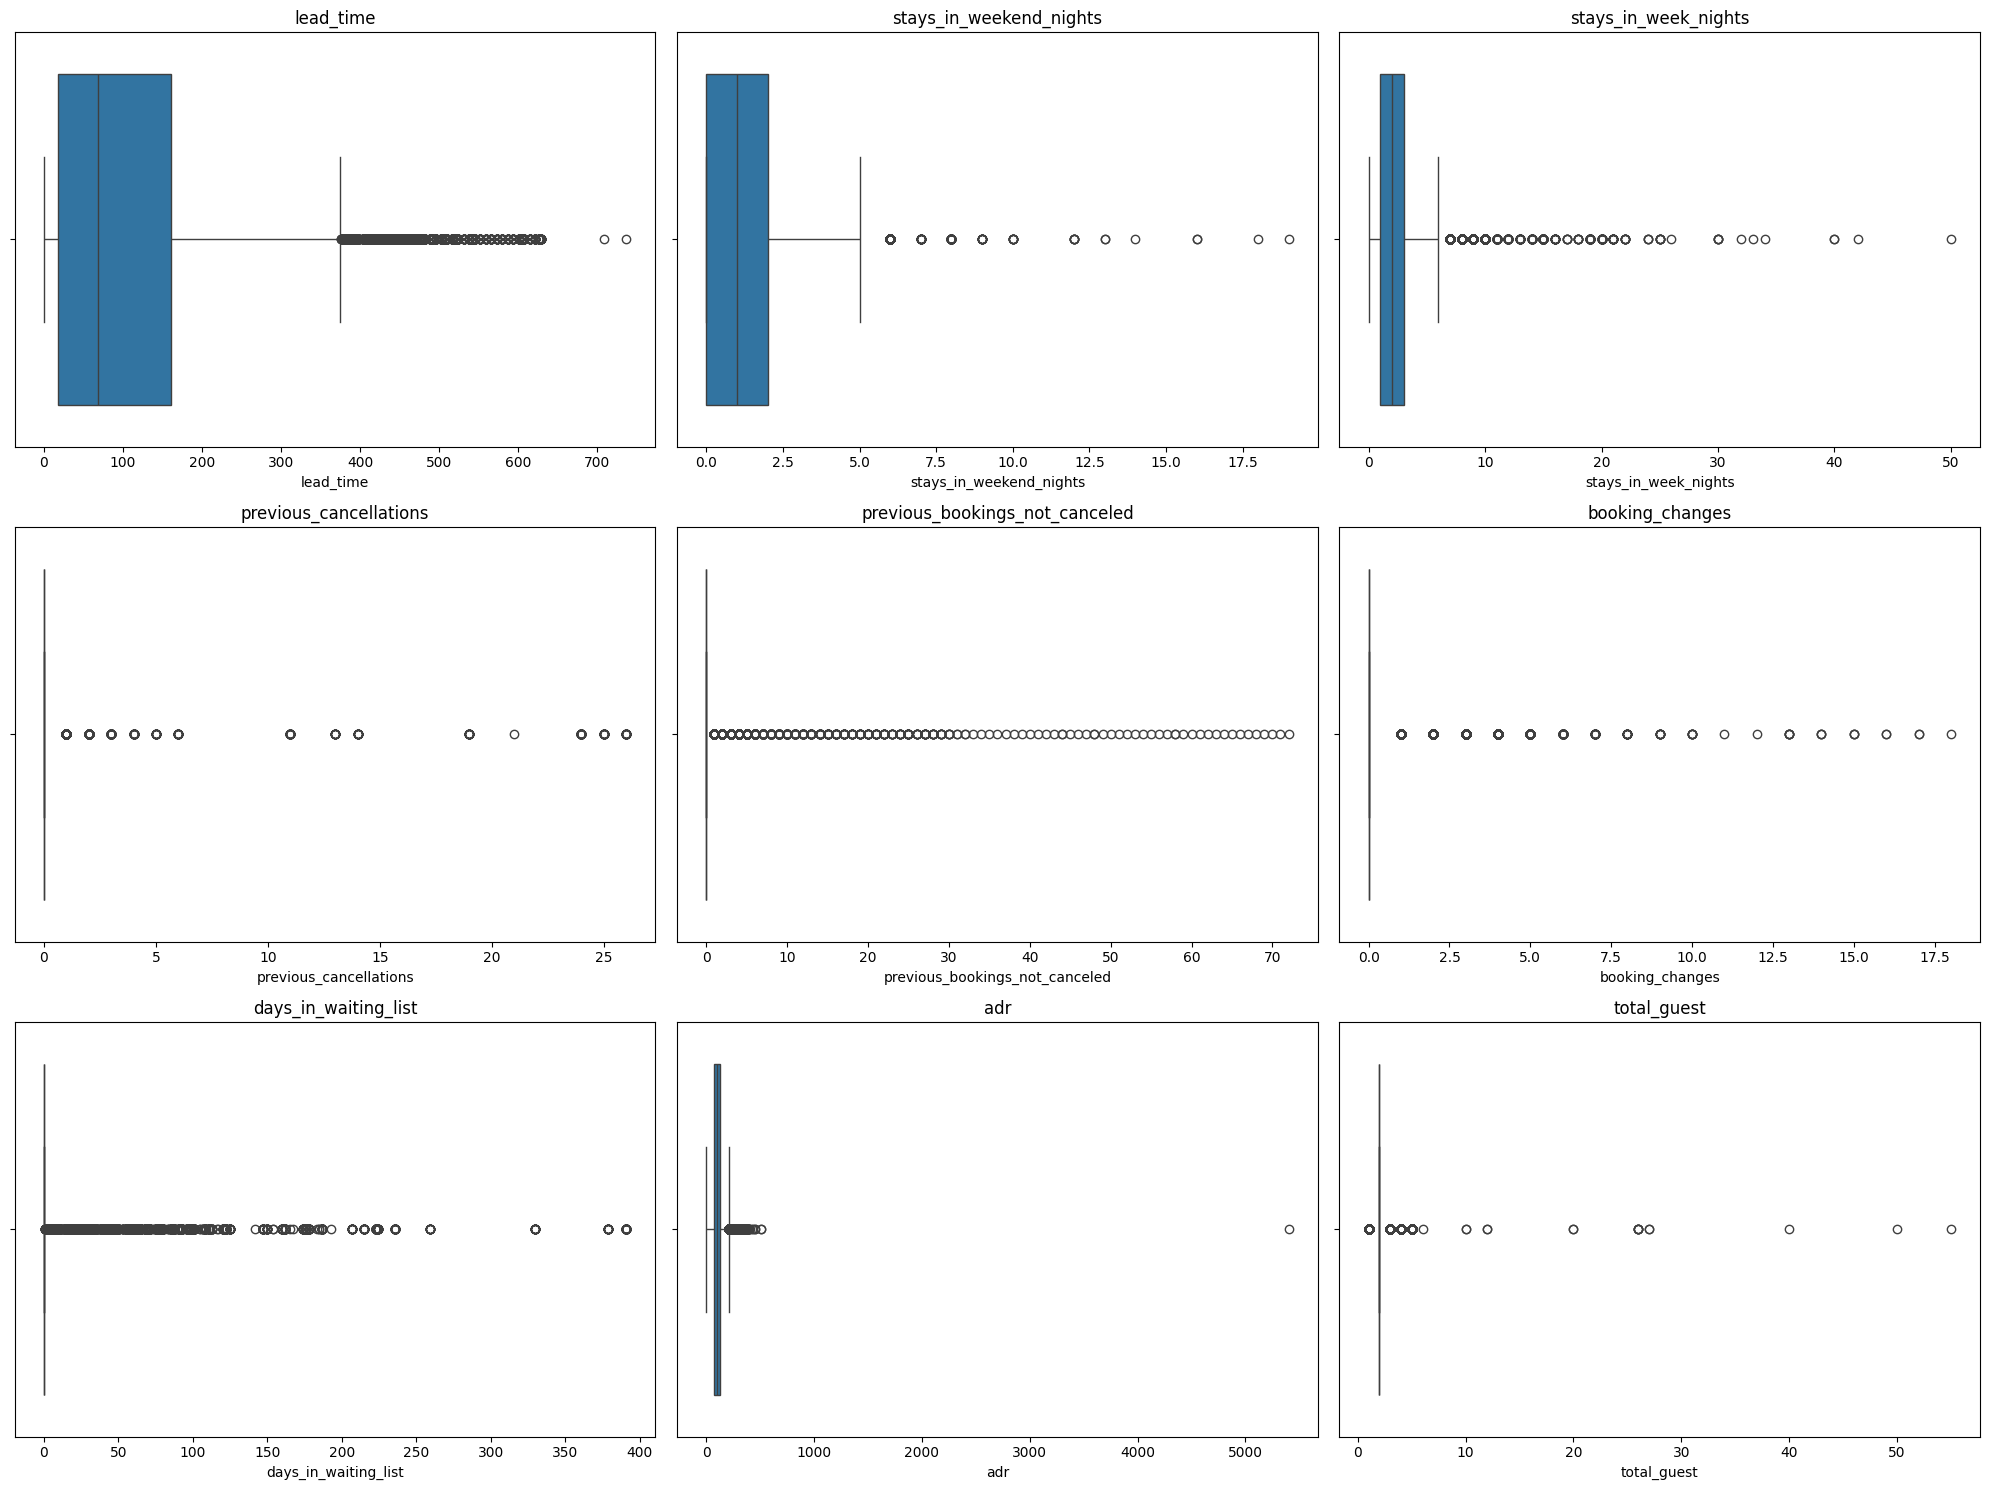

In [167]:
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(20, 5 * n_rows))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.xlabel(col)

plt.tight_layout()
plt.show()

Diketahui bahwa dataset hotel booking ini mengandung sejumlah outlier dengan distribusi yang cenderung right-skewed. Pola ini umum dijumpai pada data transaksi dan perilaku customer, khususnya dalam konteks industri perhotelan.

Secara keseluruhan, keberadaan outlier pada dataset ini tidak sepenuhnya mencerminkan kesalahan pencatatan data, melainkan menggambarkan kondisi natural dalam perilaku dan karakteristik customer dalam booking hotel. Oleh karena itu, pendekatan yang digunakan dalam analisis ini adalah tidak melakukan penghapusan outlier secara agresif, guna menjaga representasi kondisi dunia nyata.

In [168]:
def calculate_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

outlier_data = []

numerical = [var for var in df.columns if df[var].dtypes != 'object']

for column in numerical:
    outlier_result, lower_bound, upper_bound = calculate_outliers(df, column)
    total_outlier = len(outlier_result)
    outlier_percentage = round(total_outlier / len(df[column]) * 100, 2)
    outlier_data.append([column, total_outlier, outlier_percentage, lower_bound, upper_bound])

outlier_df = pd.DataFrame(outlier_data, columns=["Column", "Total Outliers", "Percentage (%)", "Lower Bound", "Upper Bound"])
outlier_df

,Column,Total Outliers,Percentage (%),Lower Bound,Upper Bound
0,is_canceled,0,0.00,-1.50,2.50
1,lead_time,2981,2.50,-196.50,375.50
2,arrival_date_year,0,0.00,2014.50,2018.50
3,arrival_date_week_number,0,0.00,-17.00,71.00
4,arrival_date_day_of_month,0,0.00,-14.50,45.50
5,stays_in_weekend_nights,258,0.22,-3.00,5.00
6,stays_in_week_nights,3330,2.79,-2.00,6.00
7,is_repeated_guest,3754,3.15,0.00,0.00
8,previous_cancellations,6479,5.43,0.00,0.00
9,previous_bookings_not_canceled,3612,3.03,0.00,0.00


In [169]:
df_outlier_removed = df.copy()

1. Variabel lead_time

In [170]:
total_data = len(df)
above_365 = df[df['lead_time'] > 365].shape[0]

print(f"Lead time > 365 days: {above_365} rows")
print(f"Percentage: {above_365 / total_data * 100:.2f}%")

Lead time > 365 days: 3147 rows
Percentage: 2.64%


In [171]:
df_leadtime_filtered = df[df['lead_time'] <= 365].copy()

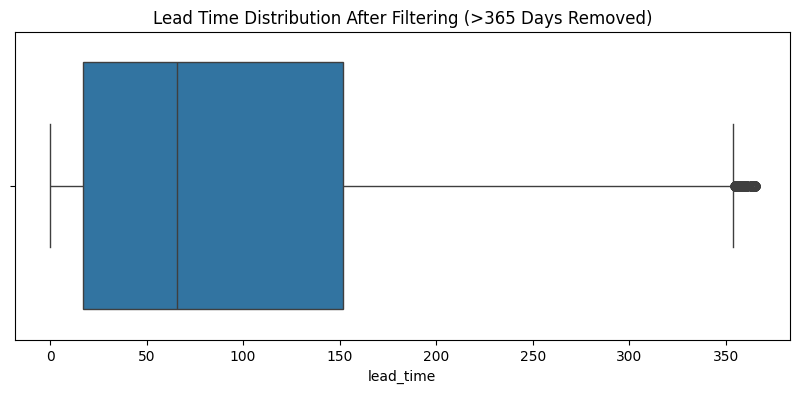

In [172]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df_leadtime_filtered['lead_time'])
plt.title('Lead Time Distribution After Filtering (>365 Days Removed)')
plt.show()

Penanganan outlier pada variabel lead_time dilakukan menggunakan pendekatan berbasis bisnis.

Secara umum, perilaku pemesanan hotel sangat jarang dilakukan lebih dari satu tahun sebelum tanggal kedatangan. Oleh karena itu dilakukan penyaringan data dengan menghapus observasi yang memiliki nilai lead_time > 365 hari.

2. Variabel previous_cancellations

In [173]:
total_data = len(df)
extreme_cancel = df[df['previous_cancellations'] > 5].shape[0]

print(f"Jumlah data previous_cancellations > 5: {extreme_cancel}")
print(f"Persentase: {extreme_cancel / total_data * 100:.2f}%")

Jumlah data previous_cancellations > 5: 202
Persentase: 0.17%


In [174]:
df = df[df['previous_cancellations'] <= 5].copy()

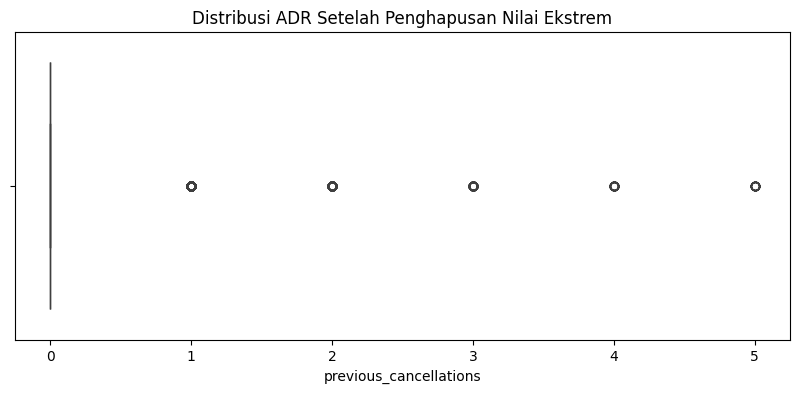

In [175]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df['previous_cancellations'])
plt.title('Distribusi ADR Setelah Penghapusan Nilai Ekstrem')
plt.show()

Dilakukan penanganan outlier menggunakan pendekatan berbasis domain dengan membatasi nilai previous_cancellations ≤ 5, guna menjaga kestabilan distribusi data tanpa menghilangkan informasi perilaku yang relevan.

3. Variabel adr

In [176]:
adr_upper = df['adr'].quantile(0.99)

In [177]:
df = df[df['adr'] <= adr_upper].copy()

Pendekatan ini hanya menghapus sekitar 1% data paling ekstrem, sehingga dampak terhadap keseluruhan dataset tetap terkontrol.

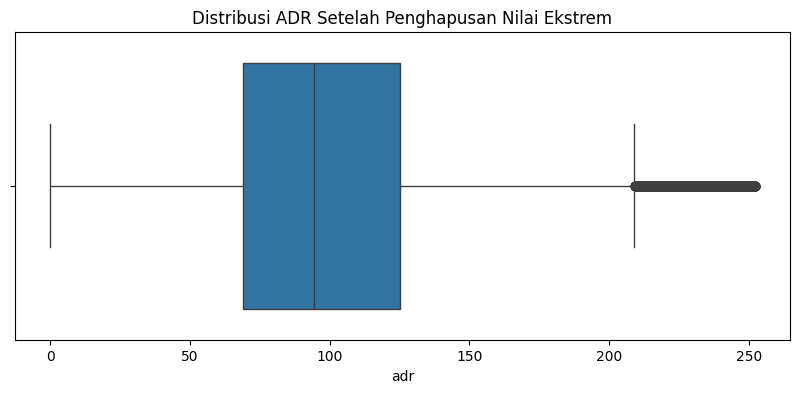

In [178]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df['adr'])
plt.title('Distribusi ADR Setelah Penghapusan Nilai Ekstrem')
plt.show()

Kuantil ke-99 digunakan sebagai batas atas untuk mengidentifikasi nilai ADR yang sangat ekstrem, di mana hanya sekitar 1% data dengan nilai tertinggi yang dihapus agar tidak mendistorsi analisis. Pendekatan ini bertujuan untuk menjaga agar analisis tetap mencerminkan distribusi harga yang realistis tanpa terdistorsi oleh nilai ekstrem.

4. Variabel days_in_waiting_list

In [179]:
total_data = len(df)
extreme_waiting = df[df['days_in_waiting_list'] > 100].shape[0]

print(f"Jumlah data days_in_waiting_list > 100: {extreme_waiting}")
print(f"Persentase: {extreme_waiting / total_data * 100:.2f}%")

Jumlah data days_in_waiting_list > 100: 745
Persentase: 0.63%


In [180]:
df = df[df['days_in_waiting_list'] <= 100].copy()

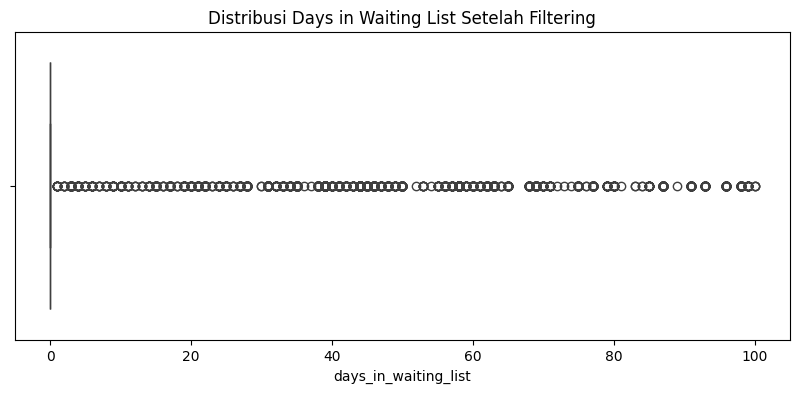

In [181]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df['days_in_waiting_list'])
plt.title('Distribusi Days in Waiting List Setelah Filtering')
plt.show()

Penanganan outlier dilakukan dengan melakukan pemotongan (upper tail trimming). Nilai ambang sebesar 100 hari dipilih karena berada jauh di atas kuantil ekstrem dan hanya mencakup sebagian sangat kecil observasi, sehingga tidak mengubah distribusi mayoritas data sekaligus mengurangi pengaruh nilai ekstrem.

## **Exploratory Data Analysis**

EDA berperan penting dalam mengetahui pola dan tren permasalahan bisnis. Dalam konteks analisis pembatalan booking hotel, dari sini kita dapat mengetahui seberapa besar cancellation ratenya, faktor-faktor apa saja yang memengaruhi keputusan pembatalan, seperti waktu pemesanan, harga, durasi menginap, type hotel, serta pola musiman dan lainnya.

🔹1. Cancellation Rate

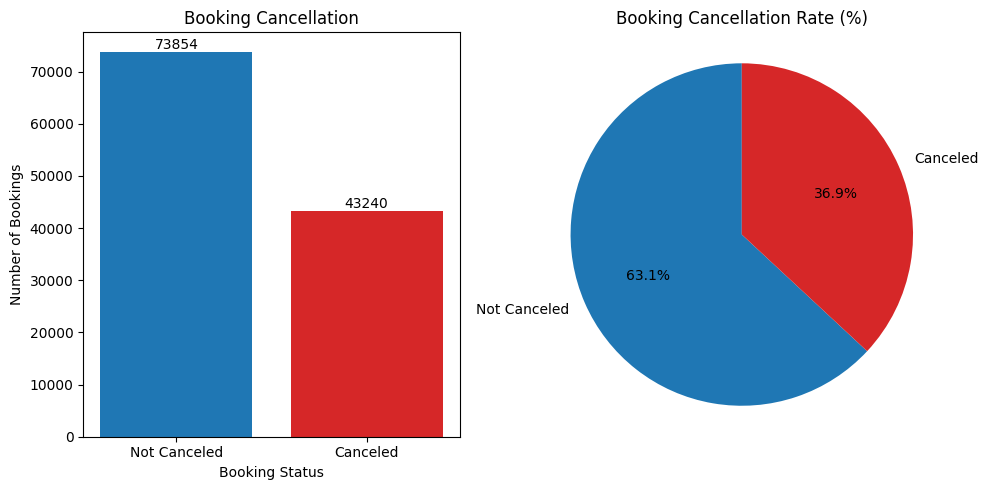

In [182]:
# Hitung data
counts = df['is_canceled'].value_counts().sort_index()
percentages = df['is_canceled'].value_counts(normalize=True).sort_index() * 100

labels = ['Not Canceled', 'Canceled']
colors = ['tab:blue', 'tab:red']

plt.figure(figsize=(10, 5))

# Bar Chart (Kiri)
plt.subplot(1, 2, 1)
bars = plt.bar(labels, counts, color=colors)
plt.title('Booking Cancellation')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom'
    )

# Pie Chart (Kanan)
plt.subplot(1, 2, 2)
plt.pie(
    percentages,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Booking Cancellation Rate (%)')
plt.axis('equal')

plt.tight_layout()
plt.show()

Diketahui bahwa sekitar **36.9%** dari total pemesanan hotel mengalami pembatalan, sementara **63.1%** booking berhasil terealisasi.

Meskipun jumlah booking yang terealisasi masih mendominasi namun proporsi cancellation rate tergolong cukup moderat. Tingkat cancellation rate sebesar **36.9%** mengindikasikan bahwa pembatalan pemesanan merupakan **permasalahan yang cukup serius** dan relevan dalam konteks bisnis perhotelan.

🔹2. Cancellation by Hotel Type

In [183]:
# Hitung rate canceled & not canceled per hotel type
hotel_status_rate = (
    df.groupby('hotel')['is_canceled']
    .value_counts(normalize=True)
    .rename('rate')
    .reset_index()
)

hotel_status_rate['rate (%)'] = (hotel_status_rate['rate'] * 100).round(2)

hotel_status_rate

,hotel,is_canceled,rate,rate (%)
0,City Hotel,0,0.583173,58.32
1,City Hotel,1,0.416827,41.68
2,Resort Hotel,0,0.726189,72.62
3,Resort Hotel,1,0.273811,27.38


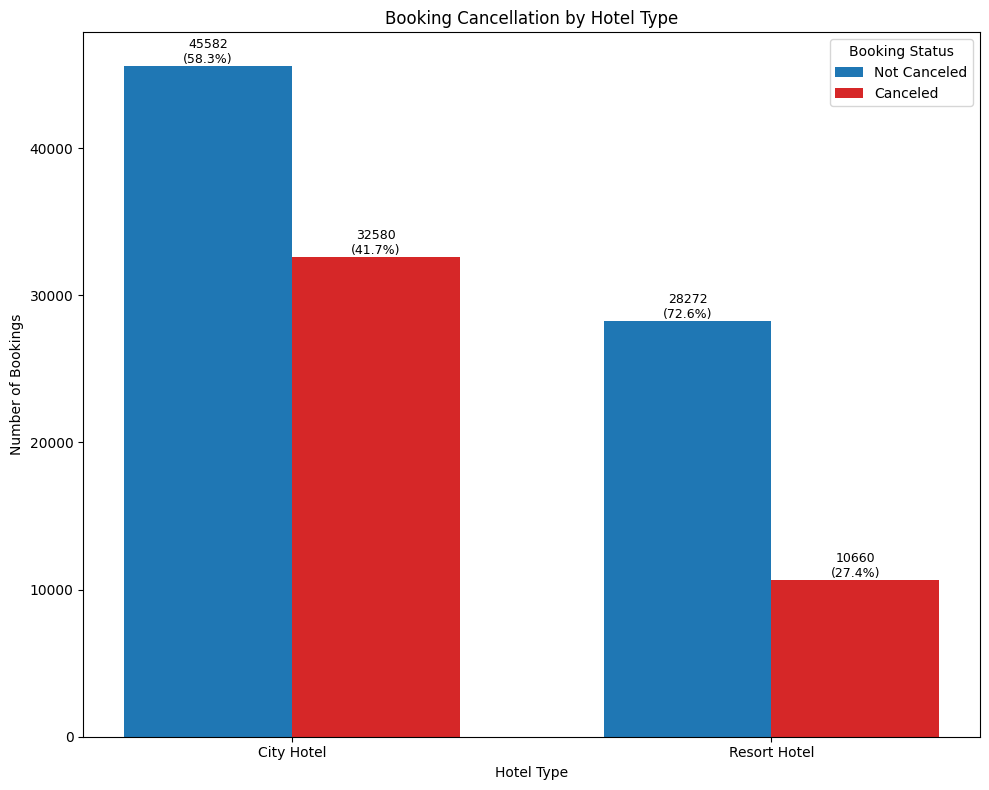

In [184]:
count_data = df.groupby(['hotel', 'is_canceled']).size().unstack()
count_data = count_data.rename(columns={0: 'Not Canceled', 1: 'Canceled'})

percentage_data = count_data.div(count_data.sum(axis=1), axis=0) * 100

x = np.arange(len(count_data.index))
width = 0.35

plt.figure(figsize=(10,8))

# Bar Not Canceled
bars_not = plt.bar(
    x - width/2,
    count_data['Not Canceled'],
    width,
    label='Not Canceled',
    color='tab:blue'
)

# Bar Canceled
bars_can = plt.bar(
    x + width/2,
    count_data['Canceled'],
    width,
    label='Canceled',
    color='tab:red'
)

plt.title('Booking Cancellation by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.xticks(x, count_data.index)
plt.legend(title='Booking Status')

for i, hotel in enumerate(count_data.index):
    # Not Canceled
    cnt_not = count_data.loc[hotel, 'Not Canceled']
    pct_not = percentage_data.loc[hotel, 'Not Canceled']

    plt.text(
        x[i] - width/2,
        cnt_not,
        f'{cnt_not}\n({pct_not:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=9
    )

    # Canceled
    cnt_can = count_data.loc[hotel, 'Canceled']
    pct_can = percentage_data.loc[hotel, 'Canceled']

    plt.text(
        x[i] + width/2,
        cnt_can,
        f'{cnt_can}\n({pct_can:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

Tingkat cancellation berdasarkan tipe hotel menunjukkan bahwa City Hotel memiliki volume pemesanan yang lebih besar dibandingkan Resort Hotel, baik untuk booking yang dibatalkan maupun yang tidak dibatalkan. Selain itu, persentase pembatalan pada City Hotel juga relatif lebih tinggi, yang mengindikasikan adanya risiko pembatalan yang lebih besar pada City Hotel dibandingkan dengan Resort Hotel.

🔹3. Arrival Month

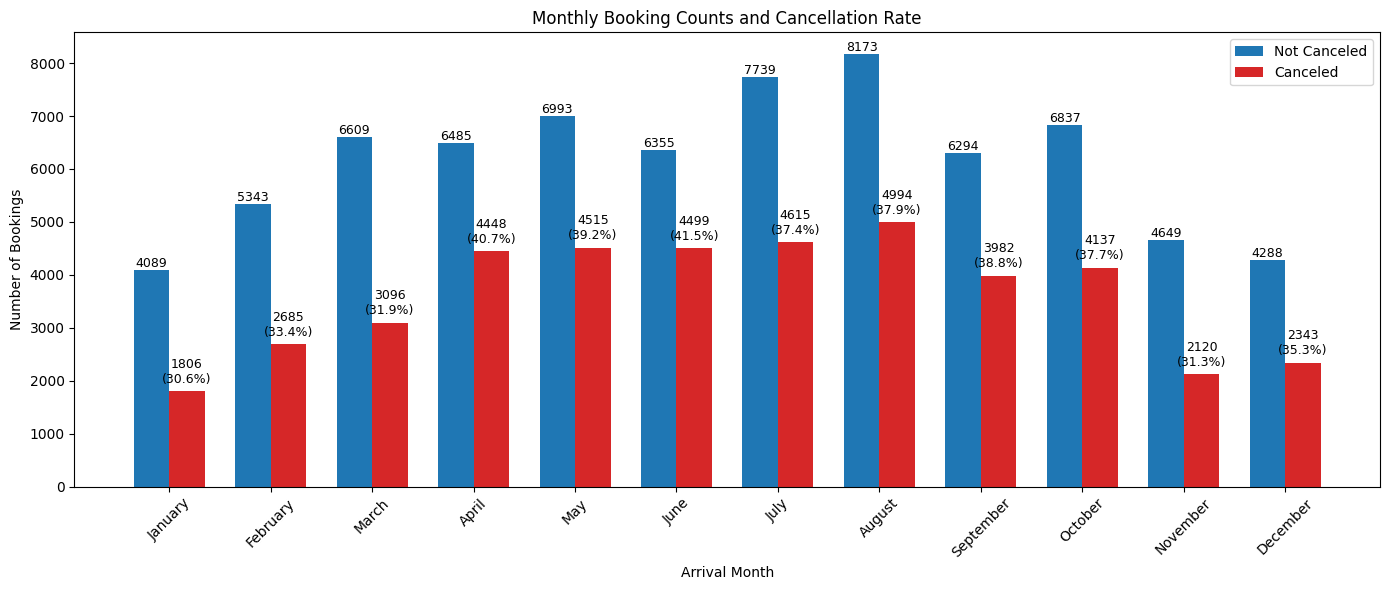

In [185]:
monthly_counts = (
    df.groupby(['arrival_date_month', 'is_canceled'])
      .size()
      .unstack(fill_value=0)
)

# Rename kolom biar jelas
monthly_counts.columns = ['Not Canceled', 'Canceled']

# Urutan bulan
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December']
monthly_counts = monthly_counts.reindex(month_order)

# Hitung total booking & cancellation rate
monthly_counts['Total'] = (
    monthly_counts['Canceled'] + monthly_counts['Not Canceled'])
monthly_counts['Cancellation Rate (%)'] = (
    monthly_counts['Canceled'] / monthly_counts['Total'] * 100)

x = np.arange(len(monthly_counts.index))
width = 0.35

plt.figure(figsize=(14,6))

# Bar Not Canceled
bars_not = plt.bar(
    x - width/2,
    monthly_counts['Not Canceled'],
    width,
    label='Not Canceled',
    color='tab:blue'
)

# Bar Canceled
bars_can = plt.bar(
    x + width/2,
    monthly_counts['Canceled'],
    width,
    label='Canceled',
    color='tab:red'
)

plt.title('Monthly Booking Counts and Cancellation Rate')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(x, monthly_counts.index, rotation=45)
plt.legend()

for bar in bars_not:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=9
    )

for i, bar in enumerate(bars_can):
    height = bar.get_height()
    rate = monthly_counts.iloc[i]['Cancellation Rate (%)']

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 100,
        f"{int(height)}\n({rate:.1f}%)",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

Berdasarkan arrival month menunjukkan adanya tingkat pembatalan yang berbeda-beda setiap bulannya. Beberapa bulan tertentu memiliki tingkat pembatalan yang lebih tinggi dibandingkan bulan lainnya, yang mengindikasikan mungkin ada faktor musiman seperti periode liburan umumnya pada pertengahan tahun, yaitu pada periode dengan permintaan tinggi (peak season).

🔹4. Market Segment

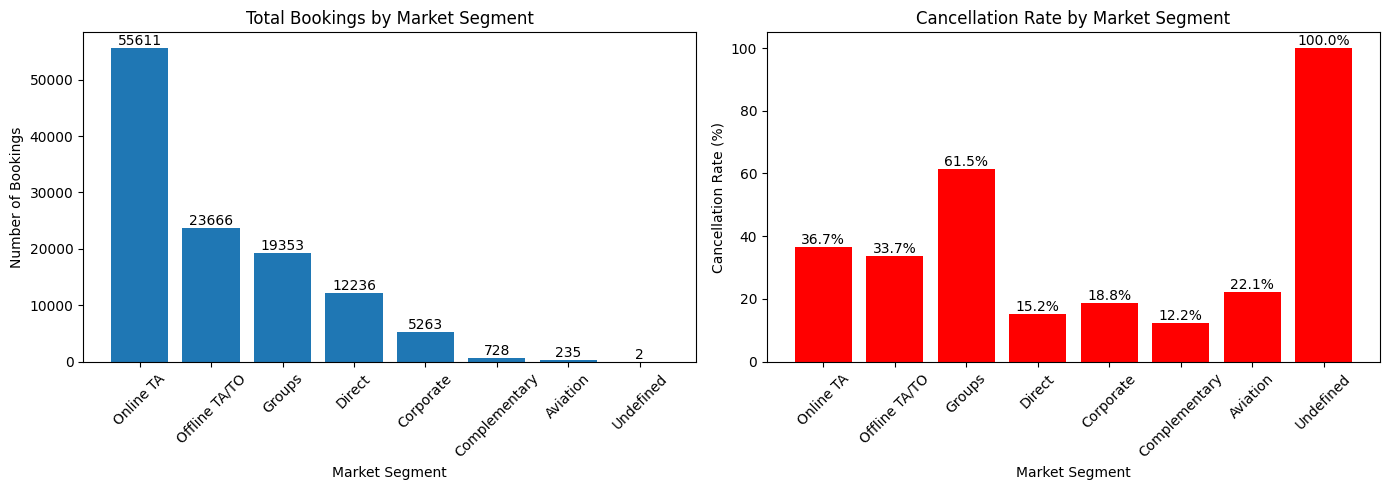

In [186]:
# Total booking per market segment
total_segment = df['market_segment'].value_counts()

# Total canceled booking per market segment
canceled_segment = df[df['is_canceled'] == 1]['market_segment'].value_counts()

# Hitung cancellation rate (%)
cancellation_rate = (canceled_segment / total_segment * 100).fillna(0)

# Urutkan berdasarkan total booking (descending)
ordered_segments = total_segment.index

total_segment = total_segment.reindex(ordered_segments)
cancellation_rate = cancellation_rate.reindex(ordered_segments)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LEFT: Total Booking
bars1 = axes[0].bar(total_segment.index, total_segment.values)
axes[0].set_title('Total Bookings by Market Segment')
axes[0].set_xlabel('Market Segment')
axes[0].set_ylabel('Number of Bookings')
axes[0].tick_params(axis='x', rotation=45)

for bar in bars1:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom'
    )

# RIGHT: Cancellation Rate
bars2 = axes[1].bar(
    cancellation_rate.index,
    cancellation_rate.values,
    color='red'
)
axes[1].set_title('Cancellation Rate by Market Segment')
axes[1].set_xlabel('Market Segment')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].tick_params(axis='x', rotation=45)

for bar in bars2:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Segment Online TA memiliki jumlah booking paling besar. Tingginya volume booking selaras dengan tingkat cancellation rate yang cukup tinggi. Hal ini umum terjadi karena platform Online memberikan fleksibilitas/kemudahan kepada customer, sehingga perubahan rencana atau pembatalan dapat dilakukan dengan lebih mudah.

Pola yang hampir serupa juga terlihat pada segment Offline TA/TO, di mana tingkat cancellation rate relatif lebih tinggi dibandingkan beberapa segment lain.

Menariknya, segment Groups menunjukkan tingkat pembatalan tertinggi, meskipun jumlah booking-nya tidak sebesar Online TA. Hal ini mengindikasikan bahwa pemesanan dalam bentuk kelompok cenderung lebih kompleks dan memiliki tingkat ketidakpastian yang lebih tinggi, sehingga lebih rentan terhadap pembatalan.

Sebaliknya, segment Direct memiliki tingkat pembatalan yang lebih rendah. Customer yang memesan langsung ke hotel umumnya sudah memiliki rencana yang lebih jelas, sehingga komitmen terhadap booking juga lebih kuat.

Untuk segment Corporate, tingkat pembatalan juga relatif rendah dan stabil. Pemesanan pada segment ini biasanya berkaitan dengan kebutuhan bisnis yang lebih terencana, sehingga kemungkinan pembatalan tidak terlalu besar.

Sementara itu, segment dengan jumlah booking yang sangat kecil seperti Aviation dan Complementary menunjukkan tingkat pembatalan yang rendah. Namun, hasil ini perlu dilihat dengan hati-hati karena keterbatasan jumlah data dapat membuat persentase terlihat lebih ekstrem atau kurang representatif.

Sedangkan cancellation rate pada segment Undefined kemungkinan disebabkan oleh ketidakjelasan klasifikasi market segment pada saat pemesanan. Ketika informasi segment tidak terdefinisi dengan baik, booking tersebut berpotensi berasal dari sumber yang kurang jelas atau proses pencatatan yang tidak konsisten, sehingga lebih rentan terhadap pembatalan.

🔹5. Deposit Type

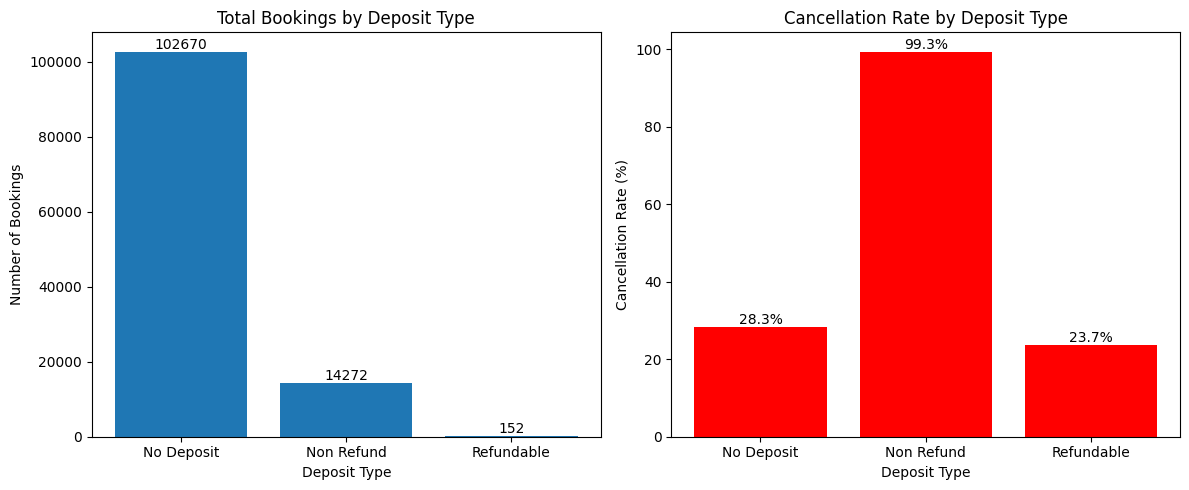

In [187]:
# Total booking per deposit type
total_deposit = df['deposit_type'].value_counts()

# Cancellation rate per deposit type
cancellation_rate_deposit = (
    df.groupby('deposit_type', observed=False)['is_canceled']
      .mean() * 100
)

# Urutkan berdasarkan total booking
ordered_deposit = total_deposit.sort_values(ascending=False).index

total_deposit = total_deposit.reindex(ordered_deposit)
cancellation_rate_deposit = cancellation_rate_deposit.reindex(ordered_deposit)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# LEFT: Total Bookings
bars1 = axes[0].bar(total_deposit.index, total_deposit.values)
axes[0].set_title('Total Bookings by Deposit Type')
axes[0].set_xlabel('Deposit Type')
axes[0].set_ylabel('Number of Bookings')

for bar in bars1:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom'
    )

# RIGHT: Cancellation Rate
bars2 = axes[1].bar(
    cancellation_rate_deposit.index,
    cancellation_rate_deposit.values,
    color='red'
)
axes[1].set_title('Cancellation Rate by Deposit Type')
axes[1].set_xlabel('Deposit Type')
axes[1].set_ylabel('Cancellation Rate (%)')

for bar in bars2:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Dapat diketahui deposit type memiliki hubungan yang kuat dengan tingkat cancellation rate, namun pola yang muncul tidak sepenuhnya sejalan dengan asumsi pada umumnya.

- Booking dengan Non Refund justru menunjukkan cancellation rate yang sangat tinggi, meskipun secara konsep kebijakan non-refundable seharusnya meningkatkan komitmen customer. Hal ini mengindikasikan bahwa pada dataset ini, booking dengan kategori Non Refund kemungkinan besar berasal dari segment pemesanan tertentu, seperti agen atau group, yang memiliki karakteristik pembatalan yang berbeda dari booking individu. Hal ini bisa kita coba pelajari lebih lanjut.

- Sementara itu, booking dengan No Deposit memiliki volume booking paling besar dengan tingkat pembatalan yang relatif lebih rendah dibandingkan Non Refund. Hal ini menunjukkan bahwa tidak semua booking tanpa deposit memiliki risiko pembatalan yang tinggi, terutama ketika pemesanan dilakukan oleh customer dengan rencana perjalanan yang jelas.

- Untuk kategori Refundable, meskipun tingkat pembatalannya relatif rendah, jumlah data yang juga terbatas membuat hasil ini perlu diinterpretasikan dengan hati-hati dan tidak dapat dijadikan acuan utama.

In [188]:
non_refund_df = df[df['deposit_type'] == 'Non Refund']

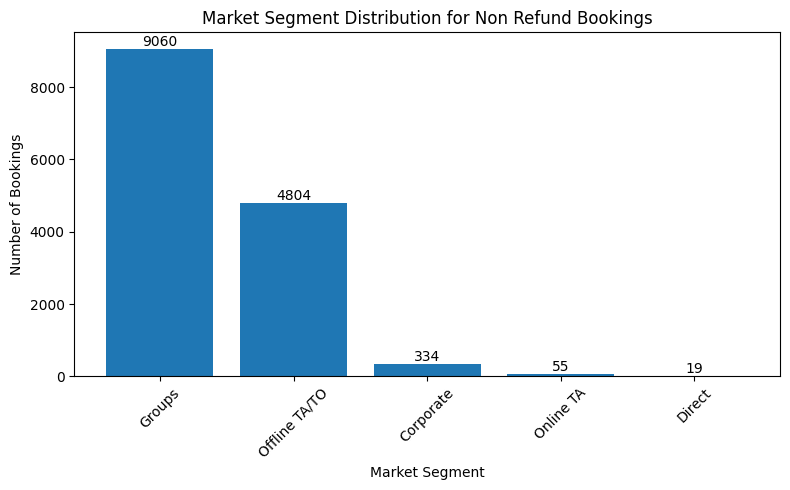

In [189]:
non_refund_segment_counts = non_refund_df['market_segment'].value_counts()

plt.figure(figsize=(8,5))
bars = plt.bar(non_refund_segment_counts.index, non_refund_segment_counts.values)
plt.xticks(rotation=45)
plt.title('Market Segment Distribution for Non Refund Bookings')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

# Tambahin angka di atas bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height)}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

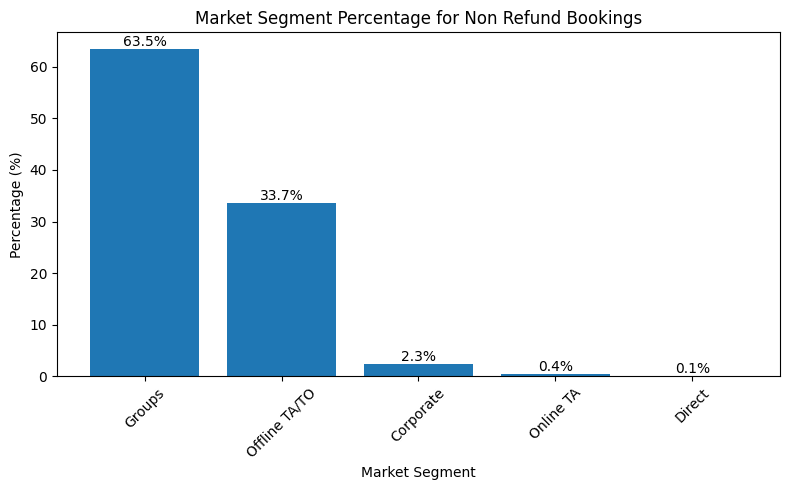

In [128]:
non_refund_segment_pct = (
    non_refund_df['market_segment']
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(8,5))
bars = plt.bar(non_refund_segment_pct.index, non_refund_segment_pct.values)
plt.xticks(rotation=45)
plt.title('Market Segment Percentage for Non Refund Bookings')
plt.xlabel('Market Segment')
plt.ylabel('Percentage (%)')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


Segment dengan deposit type Non Refund, diketahui mayoritas booking pada kategori ini didominasi oleh segment Groups dan Offline TA/TO. Secara kuantitatif, segment Groups menyumbang sekitar 62,9% dari total booking Non Refund, diikuti oleh Offline TA/TO sebesar 34,3%. Sementara itu, kontribusi dari segment lain seperti Corporate, Online TA, dan Direct relatif sangat kecil.

Dominasi segment Groups menunjukkan bahwa sebagian besar booking Non Refund kemungkinan berkaitan dengan pemesanan kelompok, yang umumnya melibatkan jumlah kamar yang besar dan perencanaan yang lebih kompleks. Kondisi ini membuat booking jenis ini lebih rentan terhadap perubahan rencana atau pembatalan secara massal, meskipun secara deposit type non-refundable yang artinya ada resiko yang harus ditanggung oleh customer.

🔹6. Lead Time

In [190]:
# Rata-rata lead time berdasarkan status cancellation
leadtime_mean = (
    df.groupby('is_canceled')['lead_time']
      .mean()
      .rename({0: 'Not Canceled', 1: 'Canceled'})
)

leadtime_mean

,lead_time
is_canceled,
Not Canceled,79.310058
Canceled,143.910060


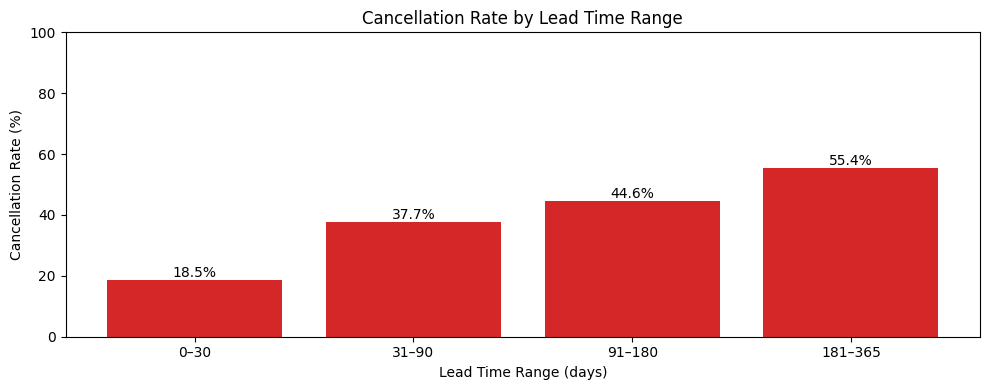

In [191]:
df['lead_time_bucket'] = pd.cut(
    df['lead_time'],
    bins=[-1, 30, 90, 180, 365],
    labels=['0–30', '31–90', '91–180', '181–365']
)

# Hitung cancellation rate
cancel_rate = (
    df.groupby('lead_time_bucket', observed=True)['is_canceled']
      .mean() * 100
)

plt.figure(figsize=(10,4))

bars = plt.bar(
    cancel_rate.index,
    cancel_rate.values,
    color='tab:red'
)

plt.title('Cancellation Rate by Lead Time Range')
plt.xlabel('Lead Time Range (days)')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Booking yang berakhir dengan pembatalan memiliki rata-rata lead time yang lebih panjang.
Hal ini menunjukkan bahwa **semakin jauh jarak waktu antara tanggal pemesanan dan tanggal kedatangan**, maka semakin besar kemungkinan booking tersebut bisa dibatalkan.

🔹7. ADR

In [192]:
# Rata-rata ADR berdasarkan status booking
adr_mean = (
    df.groupby('is_canceled')['adr']
      .mean()
      .rename({0: 'Not Canceled', 1: 'Canceled'})
)

adr_mean

,adr
is_canceled,
Not Canceled,98.379594
Canceled,103.477906


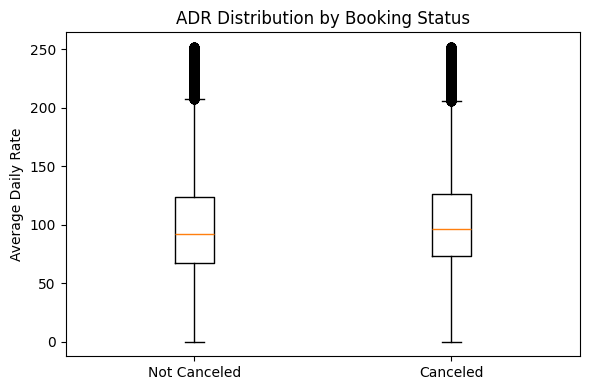

In [193]:
plt.figure(figsize=(6,4))
plt.boxplot(
    [df[df['is_canceled']==0]['adr'],
     df[df['is_canceled']==1]['adr']],
    tick_labels=['Not Canceled', 'Canceled']
)

plt.title('ADR Distribution by Booking Status')
plt.ylabel('Average Daily Rate')
plt.tight_layout()
plt.show()

Sebaran nilai **ADR (Average Daily Rate)** antara booking yang dibatalkan dan yang tidak dibatalkan menunjukkan pola yang relatif serupa, baik dari sisi median maupun rentang antar kuartil. Hal ini mengindikasikan bahwa secara umum, **harga bukan merupakan faktor utama antara reservasi yang berhasil terealisasi dan reservasi yang dibatalkan**.

Setelah dilakukan penanganan outlier pada variabel ADR, nilai-nilai ekstrem yang sebelumnya berpotensi mendistorsi distribusi data telah dihilangkan. Dengan demikian, sebaran ADR yang dianalisis saat ini merepresentasikan mayoritas perilaku pemesanan pelanggan dan memberikan gambaran yang lebih stabil serta realistis untuk keperluan analisis berikutnya.

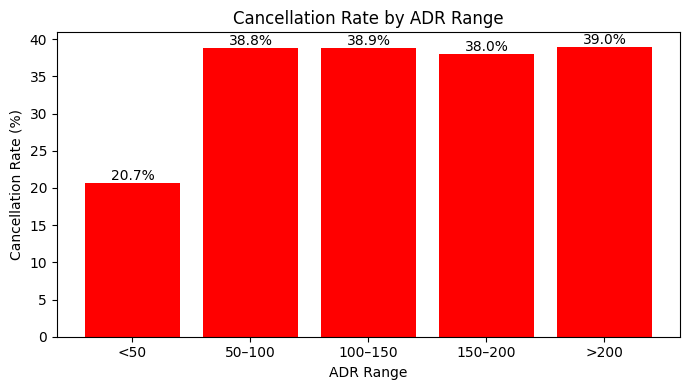

In [194]:
df['adr_bucket'] = pd.cut(
    df['adr'],
    bins=[-1, 50, 100, 150, 200, df['adr'].max()],
    labels=['<50', '50–100', '100–150', '150–200', '>200']
)

adr_cancel_rate = (
    df.groupby('adr_bucket', observed=False)['is_canceled']
      .mean() * 100
)

plt.figure(figsize=(7,4))
bars = plt.bar(
    adr_cancel_rate.index,
    adr_cancel_rate.values,
    color='red'
)

plt.title('Cancellation Rate by ADR Range')
plt.xlabel('ADR Range')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Ketika ADR dianalisis berdasarkan rentang harga, terlihat bahwa booking dengan ADR yang sangat rendah maupun sangat tinggi cenderung memiliki cancellation rate yang lebih tinggi dibandingkan rentang harga yang rendah.

🔹8. Previous Cancellations to Cancellations Rate

In [195]:
# Cek distribusi previous cancellations
df['previous_cancellations'].describe()

,previous_cancellations
count,117094.000000
mean,0.057117
std,0.256037
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,5.000000


Nilai rata-rata previous_cancellations yang sangat rendah serta dominasi nilai nol menunjukkan bahwa mayoritas pelanggan tidak memiliki riwayat pembatalan sebelumnya. Setelah penanganan outlier dilakukan, variabel ini tidak lagi mengandung nilai ekstrem dan merepresentasikan perilaku pelanggan secara lebih realistis.

🔹9. Corellation

In [196]:
month_mapping = {
    'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6,
    'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12
}

df['arrival_month_num'] = df['arrival_date_month'].map(month_mapping)

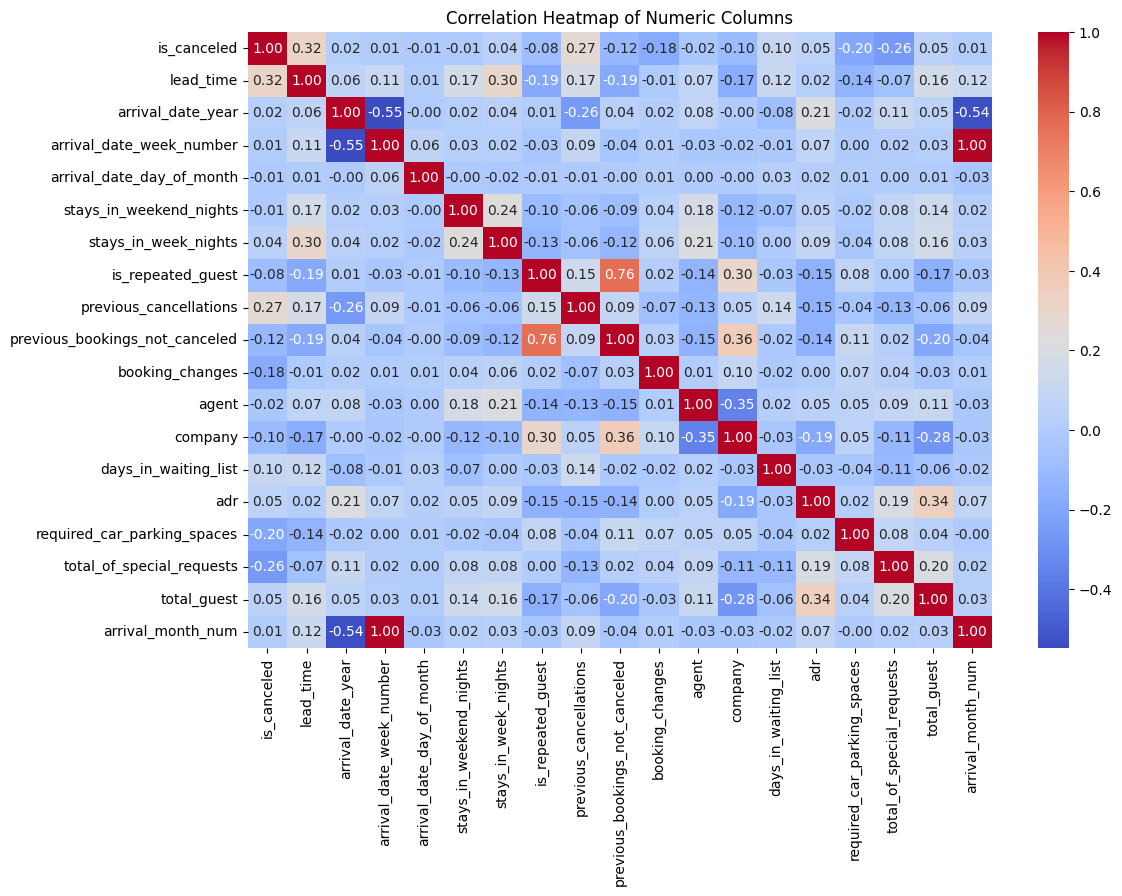

In [197]:
corr = df.select_dtypes('number').corr(method='spearman')

plt.figure(figsize=(12,8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True
)
plt.title("Correlation Heatmap of Numeric Columns")
plt.show()

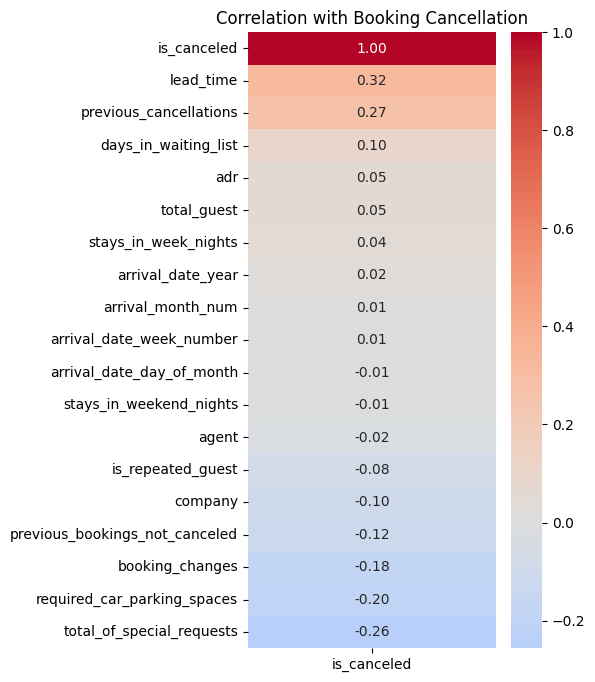

In [198]:
corr = df.select_dtypes(include='number').corr(method='spearman')
corr_target = (
    corr[['is_canceled']]
    .sort_values(by='is_canceled', ascending=False)
)

plt.figure(figsize=(4,8))
sns.heatmap(
    corr_target,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Correlation with Booking Cancellation')
plt.show()

Hasil analisis korelasi menggunakan **Spearman Correlation**, terlihat bahwa tidak ada satu pun variabel numerik yang memiliki korelasi sangat kuat terhadap pembatalan booking. Hal ini mengindikasikan bahwa keputusan pembatalan tidak dipengaruhi oleh satu faktor tunggal secara linear, melainkan oleh kombinasi beberapa faktor perilaku dan karakteristik booking.

**Variabel lead time** menunjukkan korelasi positif tertinggi terhadap pembatalan booking. Temuan ini mengindikasikan bahwa **semakin jauh jarak waktu antara pemesanan dan tanggal kedatangan, semakin tinggi kemungkinan booking dibatalkan**. Hasil ini konsisten dengan analisis sebelumnya yang menunjukkan peningkatan cancellation rate pada booking dengan lead time yang panjang.

**Variabel previous cancellations** juga memiliki korelasi positif yang cukup signifikan. Hal ini menegaskan bahwa **riwayat pembatalan di masa lalu merupakan indikator risiko yang kuat, di mana customer yang pernah melakukan pembatalan cenderung memiliki probabilitas lebih tinggi untuk kembali membatalkan booking berikutnya**.

Di sisi lain, beberapa variabel menunjukkan korelasi negatif terhadap pembatalan booking. Variabel total of special requests, required car parking spaces, dan booking changes memiliki korelasi negatif paling besar. Hal ini mengindikasikan bahwa customer yang mengajukan permintaan khusus, membutuhkan fasilitas tambahan, atau melakukan perubahan booking cenderung memiliki komitmen yang lebih tinggi terhadap pemesanan yang dilakukan.

Variabel seperti ADR, jumlah tamu, dan days in waiting list menunjukkan korelasi yang sangat lemah terhadap pembatalan booking. Temuan ini menunjukkan bahwa pengaruh variabel-variabel tersebut tidak bersifat linear.

Secara keseluruhan, analisis korelasi ini berfungsi sebagai pendukung hasil EDA, serta membantu mengidentifikasi variabel perilaku seperti lead time dan riwayat pembatalan sebagai fitur yang paling relevan untuk tahap modeling selanjutnya.

In [199]:
# Uji Normalitas
from scipy.stats import shapiro

alpha = 0.05

for col in numeric_cols:
    stat, pvalue = shapiro(df[col].sample(5000, random_state=42))

    if pvalue > alpha:
        print(
            f'{col}: p-value = {pvalue} > {alpha} → '
            f'Fail to reject H0, data can be assumed normally distributed.'
        )
    else:
        print(
            f'{col}: p-value = {pvalue} ≤ {alpha} → '
            f'Reject H0, data is not normally distributed.'
        )

lead_time: p-value = 3.03409831986436e-56 ≤ 0.05 → Reject H0, data is not normally distributed.
stays_in_weekend_nights: p-value = 4.960130426600168e-63 ≤ 0.05 → Reject H0, data is not normally distributed.
stays_in_week_nights: p-value = 3.6106806790269033e-59 ≤ 0.05 → Reject H0, data is not normally distributed.
previous_cancellations: p-value = 8.959272266652031e-90 ≤ 0.05 → Reject H0, data is not normally distributed.
previous_bookings_not_canceled: p-value = 1.642458988361202e-93 ≤ 0.05 → Reject H0, data is not normally distributed.
booking_changes: p-value = 4.9970925669452273e-85 ≤ 0.05 → Reject H0, data is not normally distributed.
days_in_waiting_list: p-value = 7.4475777769801854e-93 ≤ 0.05 → Reject H0, data is not normally distributed.
adr: p-value = 3.0591264075989907e-32 ≤ 0.05 → Reject H0, data is not normally distributed.
total_guest: p-value = 2.5342468464702913e-67 ≤ 0.05 → Reject H0, data is not normally distributed.


Uji normalitas dilakukan menggunakan Shapiro-Wilk test dengan tingkat signifikansi 5%. Mengingat ukuran dataset yang besar, pengujian dilakukan pada sampel acak untuk menghindari sensitivitas berlebih terhadap ukuran sampel. Hasil pengujian menunjukkan bahwa sebagian besar fitur numerik tidak terdistribusi normal.

### **Conclusion**

Berdasarkan keseluruhan proses analisis eksploratif data (Exploratory Data Analysis), dapat disimpulkan bahwa fenomena booking cancellation dalam industri perhotelan tidak terjadi begitu saja, melainkan dipengaruhi oleh pola perilaku customer dan karakteristik pemesanan yang dapat diidentifikasi secara jelas melalui data.

Hasil analisis menunjukkan bahwa variabel-variabel yang merepresentasikan potensi cancellations dan fleksibilitas pemesanan, seperti lead time yang panjang, riwayat perubahan pemesanan, status waiting list, jenis deposit, serta market segment, memiliki keterkaitan yang konsisten terhadap meningkatnya kemungkinan pembatalan. Hal ini mengindikasikan bahwa semakin rendah tingkat komitmen awal customer terhadap pemesanan, semakin tinggi risiko terjadinya pembatalan.

Secara keseluruhan, hasil EDA ini membuktikan bahwa dataset telah melalui proses pembersihan yang memadai, memiliki kualitas data yang cukup baik, serta mengandung sinyal yang relevan dan informatif untuk digunakan pada tahap pemodelan prediktif. Dengan demikian, analisis ini memberikan landasan yang kuat baik dari sisi pemahaman bisnis maupun pengembangan model machine learning dalam upaya memprediksi dan memitigasi risiko pembatalan pemesanan hotel.

### **Insight**

1️⃣ **Pembatalan booking lebih dipengaruhi oleh tingkat komitmen pelanggan dibandingkan harga kamar.**
Faktor seperti lead time yang panjang, tidak adanya deposit, dan pemesanan melalui OTA lebih menentukan risiko pembatalan dibandingkan perbedaan ADR.

2️⃣ **Lead time merupakan indikator risiko pembatalan yang paling kuat.**
Semakin jauh jarak waktu antara pemesanan dan tanggal kedatangan, semakin tinggi ketidakpastian dan peluang pembatalan.

3️⃣ **Segmen OTA memiliki volume booking tinggi namun juga tingkat pembatalan yang lebih besar.**
Hal ini mencerminkan perilaku pelanggan OTA yang lebih fleksibel dan sensitif terhadap perubahan rencana.

4️⃣ **Penerapan deposit efektif menurunkan tingkat pembatalan.**
Baik refundable maupun non-refundable deposit menunjukkan risiko pembatalan yang lebih rendah dibandingkan booking tanpa deposit.

5️⃣ **Pembatalan booking merupakan hasil interaksi berbagai faktor.**
Kombinasi lead time, deposit type, market segment, hotel type, dan faktor musiman membentuk pola pembatalan yang jelas dan dapat diprediksi.